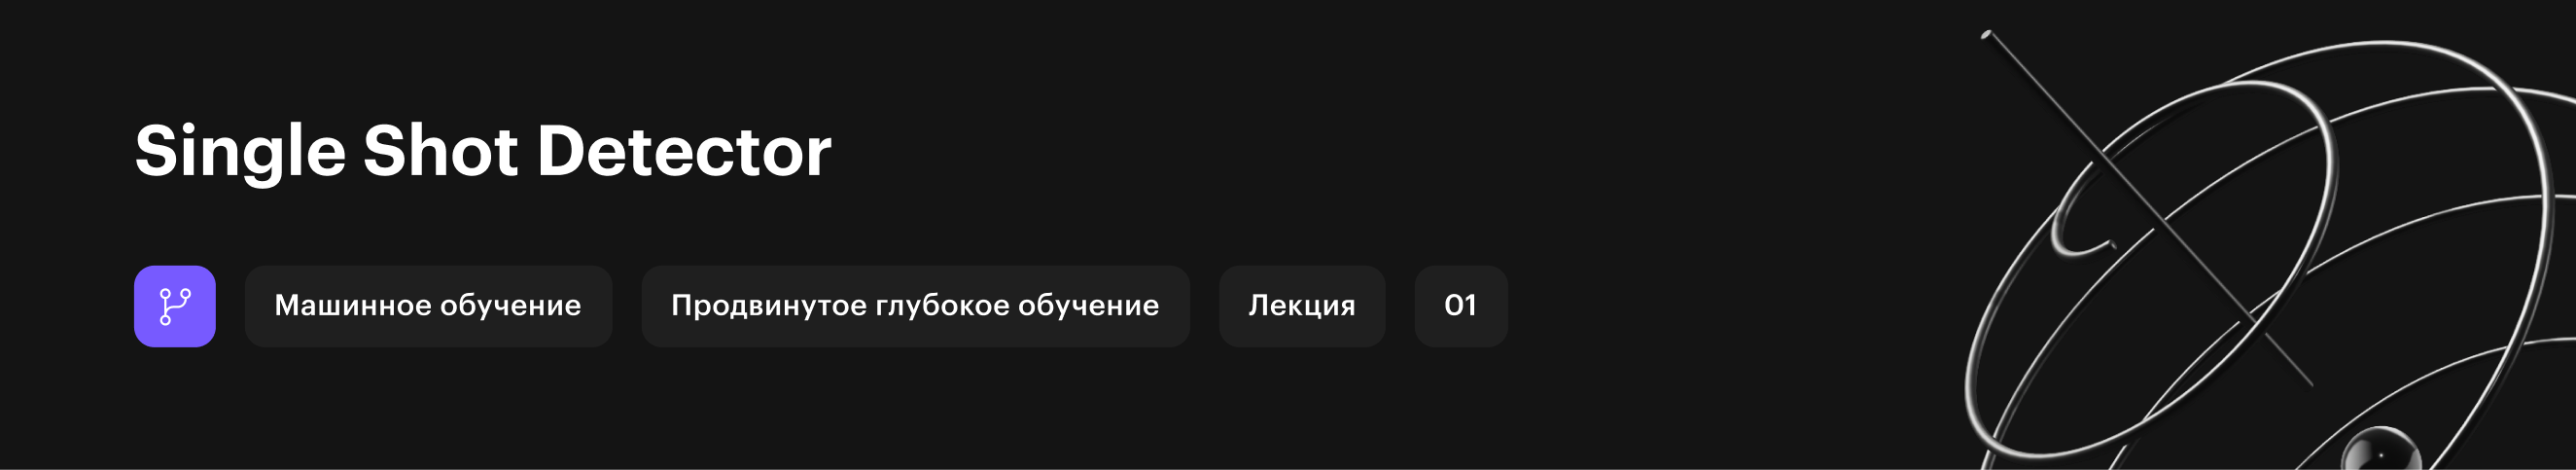

## Single Shot Detector

## План
1. Предварительные сведения
2. Задача классификации и детектирования объектов
3. Модель Single Shot Detector
4. Функция потерь MultiBox Loss
5. Тренировка модели
6. Тестирование модели

In [ ]:
import matplotlib.pyplot   as plt
import torch.nn.functional as F
import torchvision
import colorsys
import random
import torch
import cv2

from matplotlib.patches import Polygon
from matplotlib         import patches, lines
from torch              import nn
from PIL                import Image

import albumentations as alb
import numpy          as np
import scipy          as sp

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

import warnings
warnings.filterwarnings('ignore')

## 1. Предварительные сведения

### Глубокие модели

<img src="...
A7jXPOaoLZleAAAAAElFTkSuQmCC
" alt="drawing" width="700"/>

### Рецептивное поле в глубоких моделях

<img src="...
AEAU/w9EKwWxKc+C3AAAAABJRU5ErkJggg==
" alt="drawing" width="700"/>

### Одна модель -> несколько задач (классификация и регрессия)

<img src="..." alt="drawing" width="690"/>

### 2. Задача классификации и детектирования объектов

Задача, в рамках которой необходимо выделить требуемые объекты на изображении посредством нахождения координат их ограничивающих рамок и классификации этих ограничивающих рамок из множества заранее известных классов.

In [ ]:
#!gdown --id 186AOFCzONFpFxPTF5zsAPFabEJNC5siF -O sample.jpg

In [ ]:
COCO_CLASSES = (
 "background","person","bicycle","car",
 "motorcycle","airplane","bus","train",
 "truck","boat","traffic light","fire hydrant",
 "street sign","stop sign","parking meter",
 "bench","bird","cat","dog","horse","sheep",
 "cow","elephant","bear","zebra","giraffe",
 "hat","backpack","umbrella","shoe",
 "eye glasses","handbag","tie","suitcase",
 "frisbee","skis","snowboard","sports ball",
 "kite","baseball bat","baseball glove",
 "skateboard","surfboard","tennis racket",
 "bottle","plate","wine glass","cup",
 "fork","knife","spoon","bowl","banana",
 "apple","sandwich","orange","broccoli",
 "carrot","hot dog","pizza","donut",
 "cake","chair","couch","potted plant",
 "bed","mirror","dining table","window",
 "desk","toilet","door","tv", "laptop",
 "mouse","remote","keyboard","cell phone",
 "microwave","oven","toaster","sink",
 "refrigerator","blender","book","clock",
 "vase","scissors","teddy bear","hair drier",
 "toothbrush","hair brush"
)

In [ ]:
!wget https://github.com/SergeyMalashenko/2024-ML3/raw/main/seminars/07_ssd/sample.jpg

In [ ]:
from torchvision.models.detection import SSD300_VGG16_Weights
from torchvision.utils            import draw_bounding_boxes

import albumentations.pytorch.transforms

model = torchvision.models.detection.ssd300_vgg16(weights=SSD300_VGG16_Weights.DEFAULT)
model.eval()

bbox_params = alb.BboxParams(format='albumentations', min_area=1, min_visibility=0.5, label_fields=['labels'])
image_transform = alb.Compose([
    alb.augmentations.geometric.resize.Resize(height=300, width=300),
    alb.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    alb.pytorch.transforms.ToTensorV2()
], bbox_params=bbox_params, p=1.0)

source_path    = "sample.jpg"
source_pil     = Image.open(source_path) #PIL image
source_numpy   = np.array  (source_pil ) #Numpy array

source_bbox_s, source_label_s = [( 0, 0, 1, 1),], [0,]

result_dict = image_transform(image=source_numpy, bboxes=source_bbox_s, labels=source_label_s )

target_torch   = result_dict['image' ]
target_bbox_s  = result_dict['bboxes']
target_label_s = result_dict['labels']

In [ ]:
predictions = model( [target_torch] )

Результат есть словарь, который имеет следующие поля:

* `boxes`  — оценка кооординат прямоугольников $(x_{min}, y_{min}, x_{max}, y_{max})$;
* `scores` — максимальная оценка принадлежности классу   $max\_val(p_1, p_2, ..., p_N)$;
* `labels` — метка класса объекта   $arg\_max(p_1, p_2, ..., p_N)$.

In [ ]:
predictions[0].keys()

In [ ]:
result_box_s   = predictions[0]['boxes' ]
result_score_s = predictions[0]['scores']
result_label_s = predictions[0]['labels']

result_class_s = [ COCO_CLASSES[result_label] for result_label in result_label_s ]

Построим гистограмму оценок принадлежности классам.

In [ ]:
result_score_s

In [ ]:
from matplotlib.pyplot import hist, boxplot, violinplot

fig, ax = plt.subplots(nrows=1, ncols=1)
ax.hist(result_score_s.detach().numpy())
ax.set_xlabel('score')
plt.show()

In [ ]:
from torchvision.transforms.functional import to_pil_image

def show(imgs):
    if not isinstance(imgs, list):
        imgs = [imgs]
    fix, axs = plt.subplots(ncols=len(imgs), squeeze=False, figsize=(15, 15))
    for i, img in enumerate(imgs):
        img = img.detach()
        img = to_pil_image(img.to('cpu'))
        axs[0, i].imshow(np.asarray(img))
        axs[0, i].set(xticklabels=[], yticklabels=[], xticks=[], yticks=[])

In [ ]:
from torchvision.transforms.functional import convert_image_dtype
from torchvision.utils                 import draw_bounding_boxes
from torchvision.io                    import read_image
from torchvision.transforms.functional import resize

result_color_s = ["blue"]*result_box_s.shape[0]
result_image   = resize(read_image(source_path), (300,300))

result = draw_bounding_boxes(
    convert_image_dtype(result_image , dtype=torch.uint8),
    result_box_s, colors=result_color_s, labels=result_class_s, width=1)
show(result)

In [ ]:
from torchvision.transforms.functional import convert_image_dtype
from torchvision.utils                 import draw_bounding_boxes
from torchvision.io                    import read_image
from torchvision.transforms.functional import resize

score_threshold = torch.quantile(result_score_s, q = 0.95)
index_s = result_score_s > score_threshold

current_box_s   = predictions[0]['boxes' ][index_s]
current_score_s = predictions[0]['scores'][index_s]
current_label_s = predictions[0]['labels'][index_s]
current_class_s = [ COCO_CLASSES[current_label] for current_label in current_label_s ]

current_color_s = ["blue"]*current_box_s.shape[0]
current_image   = resize(read_image(source_path), (300,300))

result = draw_bounding_boxes(
    convert_image_dtype(result_image , dtype=torch.uint8),
    current_box_s, colors=current_color_s, labels=current_class_s, width=1)
show(result)

Какие особенности имеются в задаче?

### 3. Модель Single Shot Detector

`SSD (Single Shot Detector)` — одна из популярных `one-stage`-моделей детектирования объектов вместе с `Mask-RCNN` и `YOLOv3`. Модель обладает высокой скоростью, а также хорошей точностью.

Когда что-то изучаете, хорошо обращаться к истокам — то есть к [оригинальной статье](https://arxiv.org/pdf/1512.02325.pdf). В статье представлены две версии модели — `SSD300`, `SSD512`, которые различаются размером входа и некоторыми параметрами (конечно, `SSD512` массивнее и точнее), мы же сегодня рассмотрим `SSD300`.

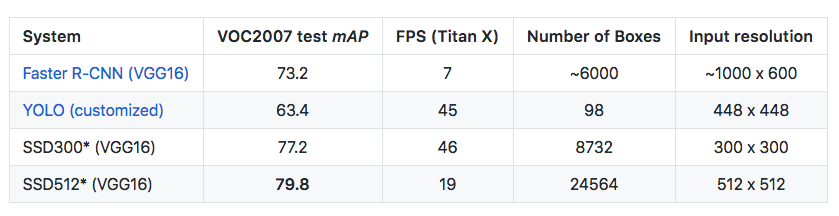

**Основные концепции, которые надо помнить и понимать, чтобы работать с моделью SSD:**
 - `feature maps `,
 - `intersection over union`,
 - `prior boxes`,
 - `hard negative mining`,
 - `non-maximum suppression`,
 - `average precision`,
 - `multibox loss` (`localization + classification`).

### **Архитектура SSD (vgg + convs + priors)**

Для простоты слои в SSD можно разделить на три группы: `backbone` (`базовые свёрточные слои`), `auxiliary convolutions` (`вспомогательные свёрточные слои`) и `prediction convolutions` (`предсказательные свёрточные слои`).

- **`Backbone`** — основа получаемого признакового представления, обычно предобученная на `ImageNet` модель. У `SSD` изначально `VGG16`, но менять её можно (и нужно) в зависимости от ваших желаний.
- **`Auxiliary`**-часть — навешанные после `backbone` конволюции для получения новых, более глубоких `feature maps`.
- **`Prediction`**-часть — конволюции, на основе которых мы получаем предсказания по локализации и классификации объектов.
- **`Priors`** в явном виде НЕ ВКЛЮЧЕНЫ в архитектуру, только их количество, но в обучении они играют важнейшую роль.

### **Backbone — VGG16**



Вспомним как выглядит классическая `VGG16` архитектура.

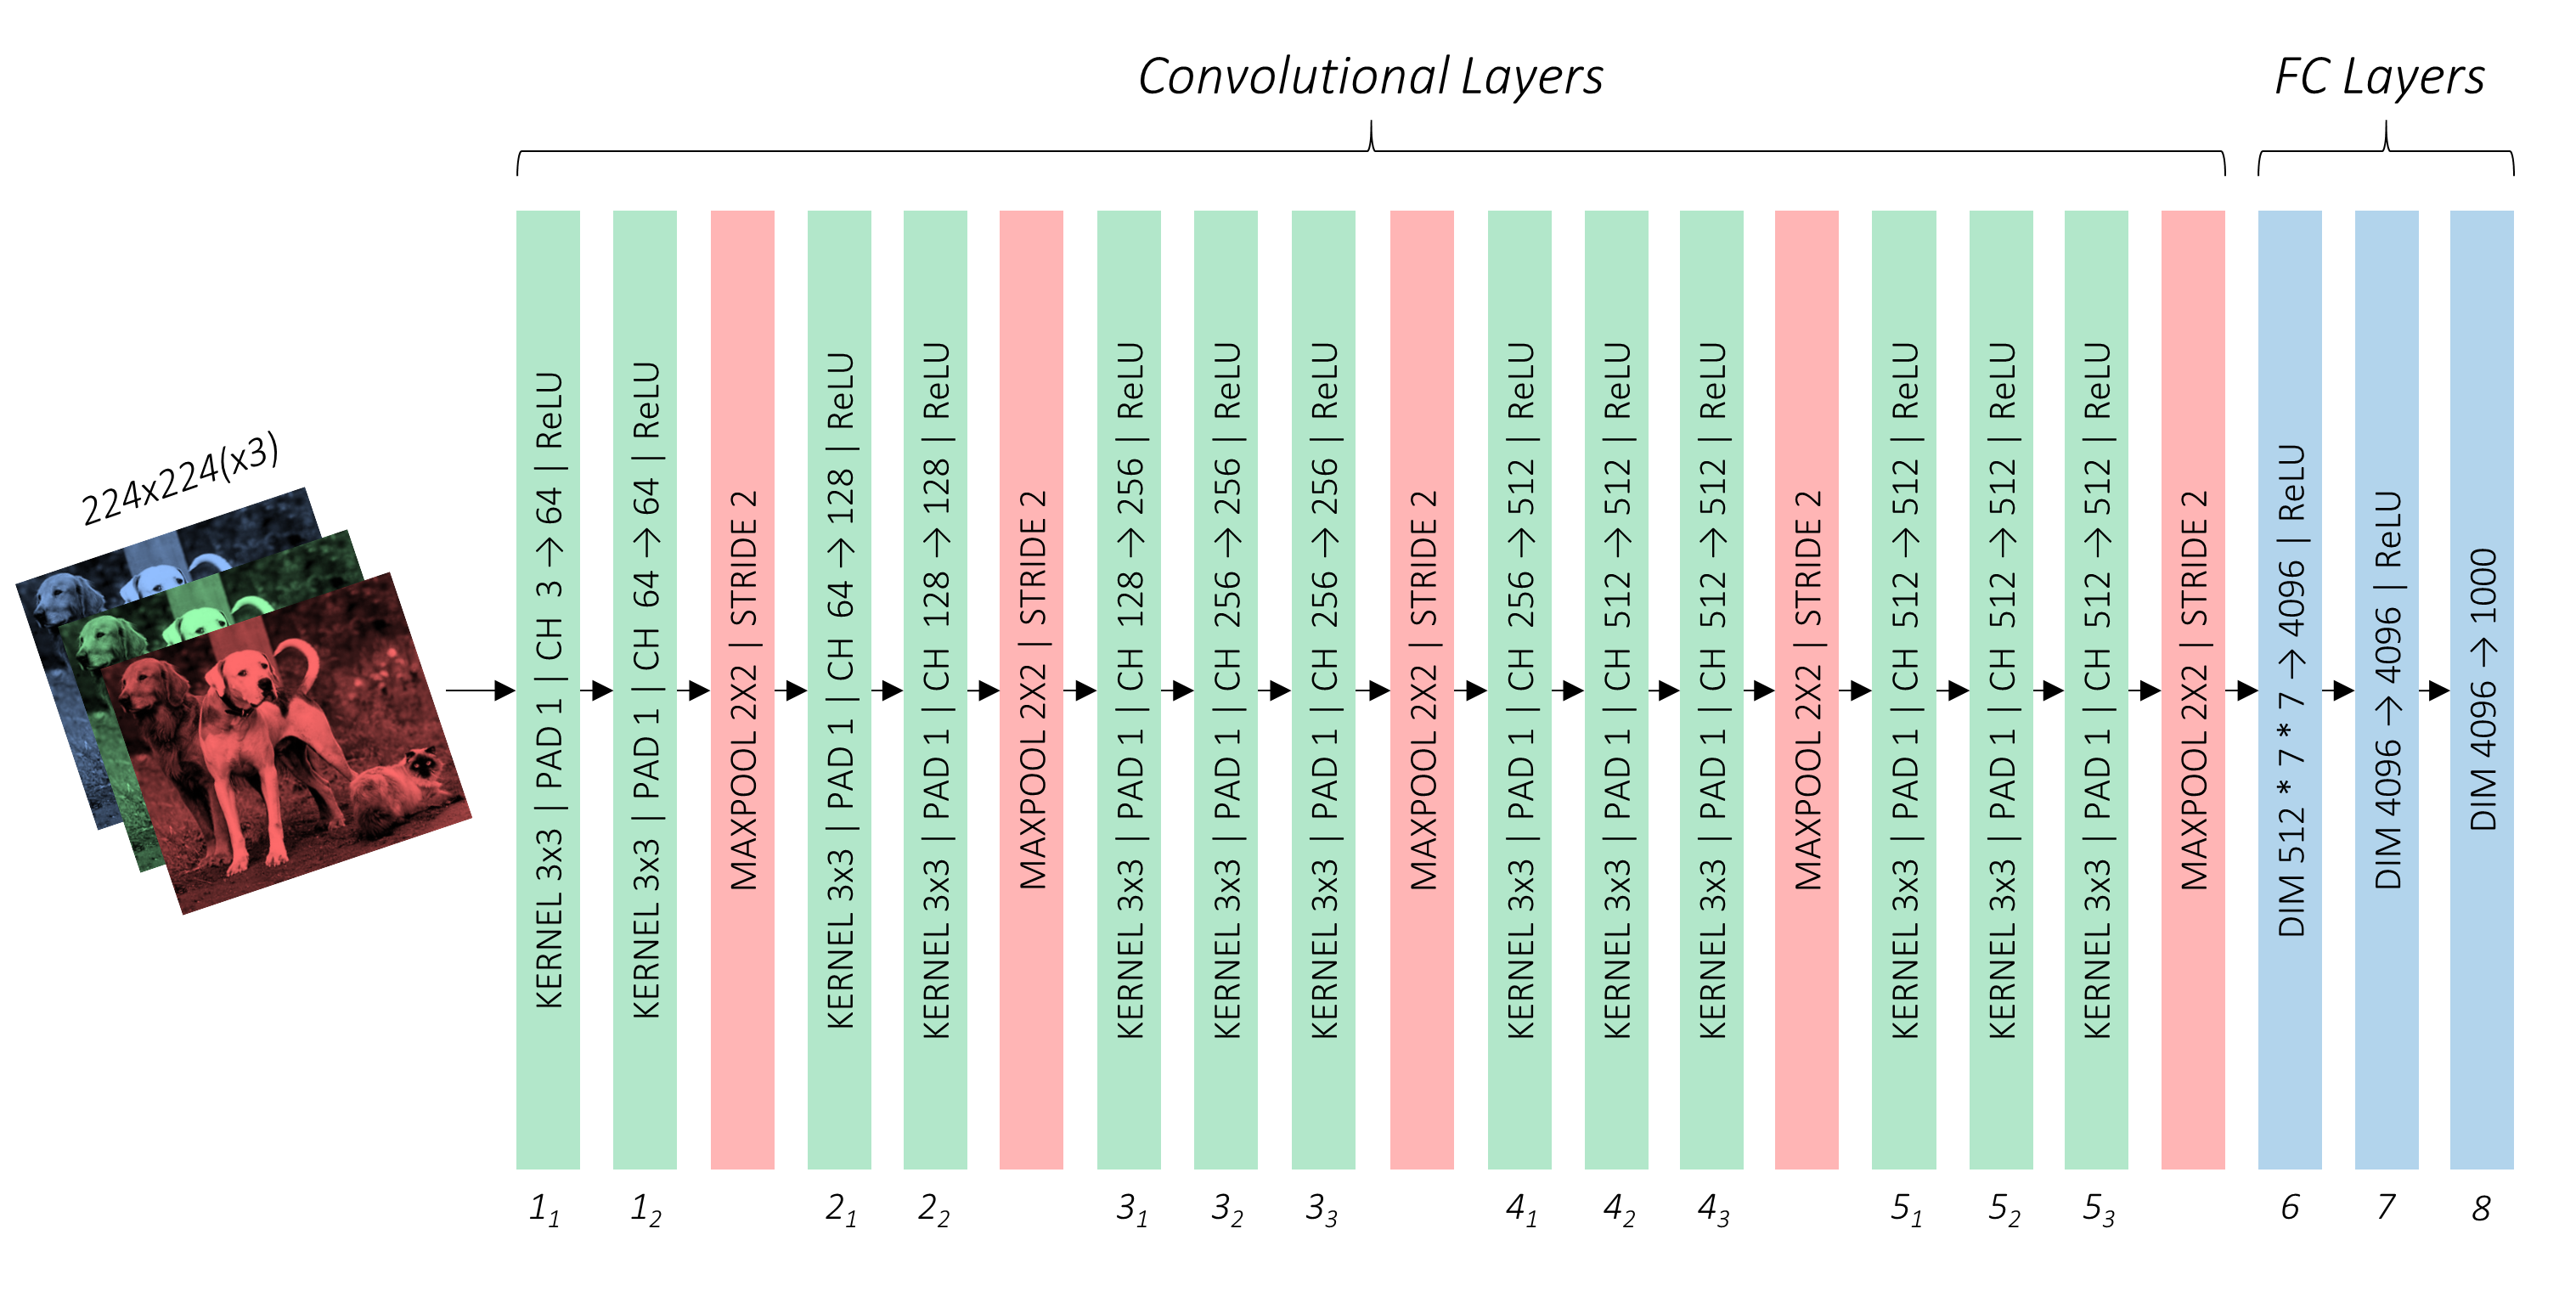

В `SSD` в архитектуру `VGG16` внесены некоторые **изменения**:
 - `input` теперь `(300, 300, 3)`;
 - `MaxPool_3` при вычислении размера `output` использует `ceiling` функцию вместо дефолтной ([`ceil_mode=True`](https://pytorch.org/docs/stable/generated/torch.nn.MaxPool2d.html)). Это сделано, просто чтобы размер `output` стал `(38, 38)` вместо `(37, 37)`;
 - `MaxPool_5: kernel=(2, 2), stride=2 -> kernel(3, 3), stride=1`. То есть теперь не урезает размерность в 2 раза;
 - `FC`-слои нам не нужны.

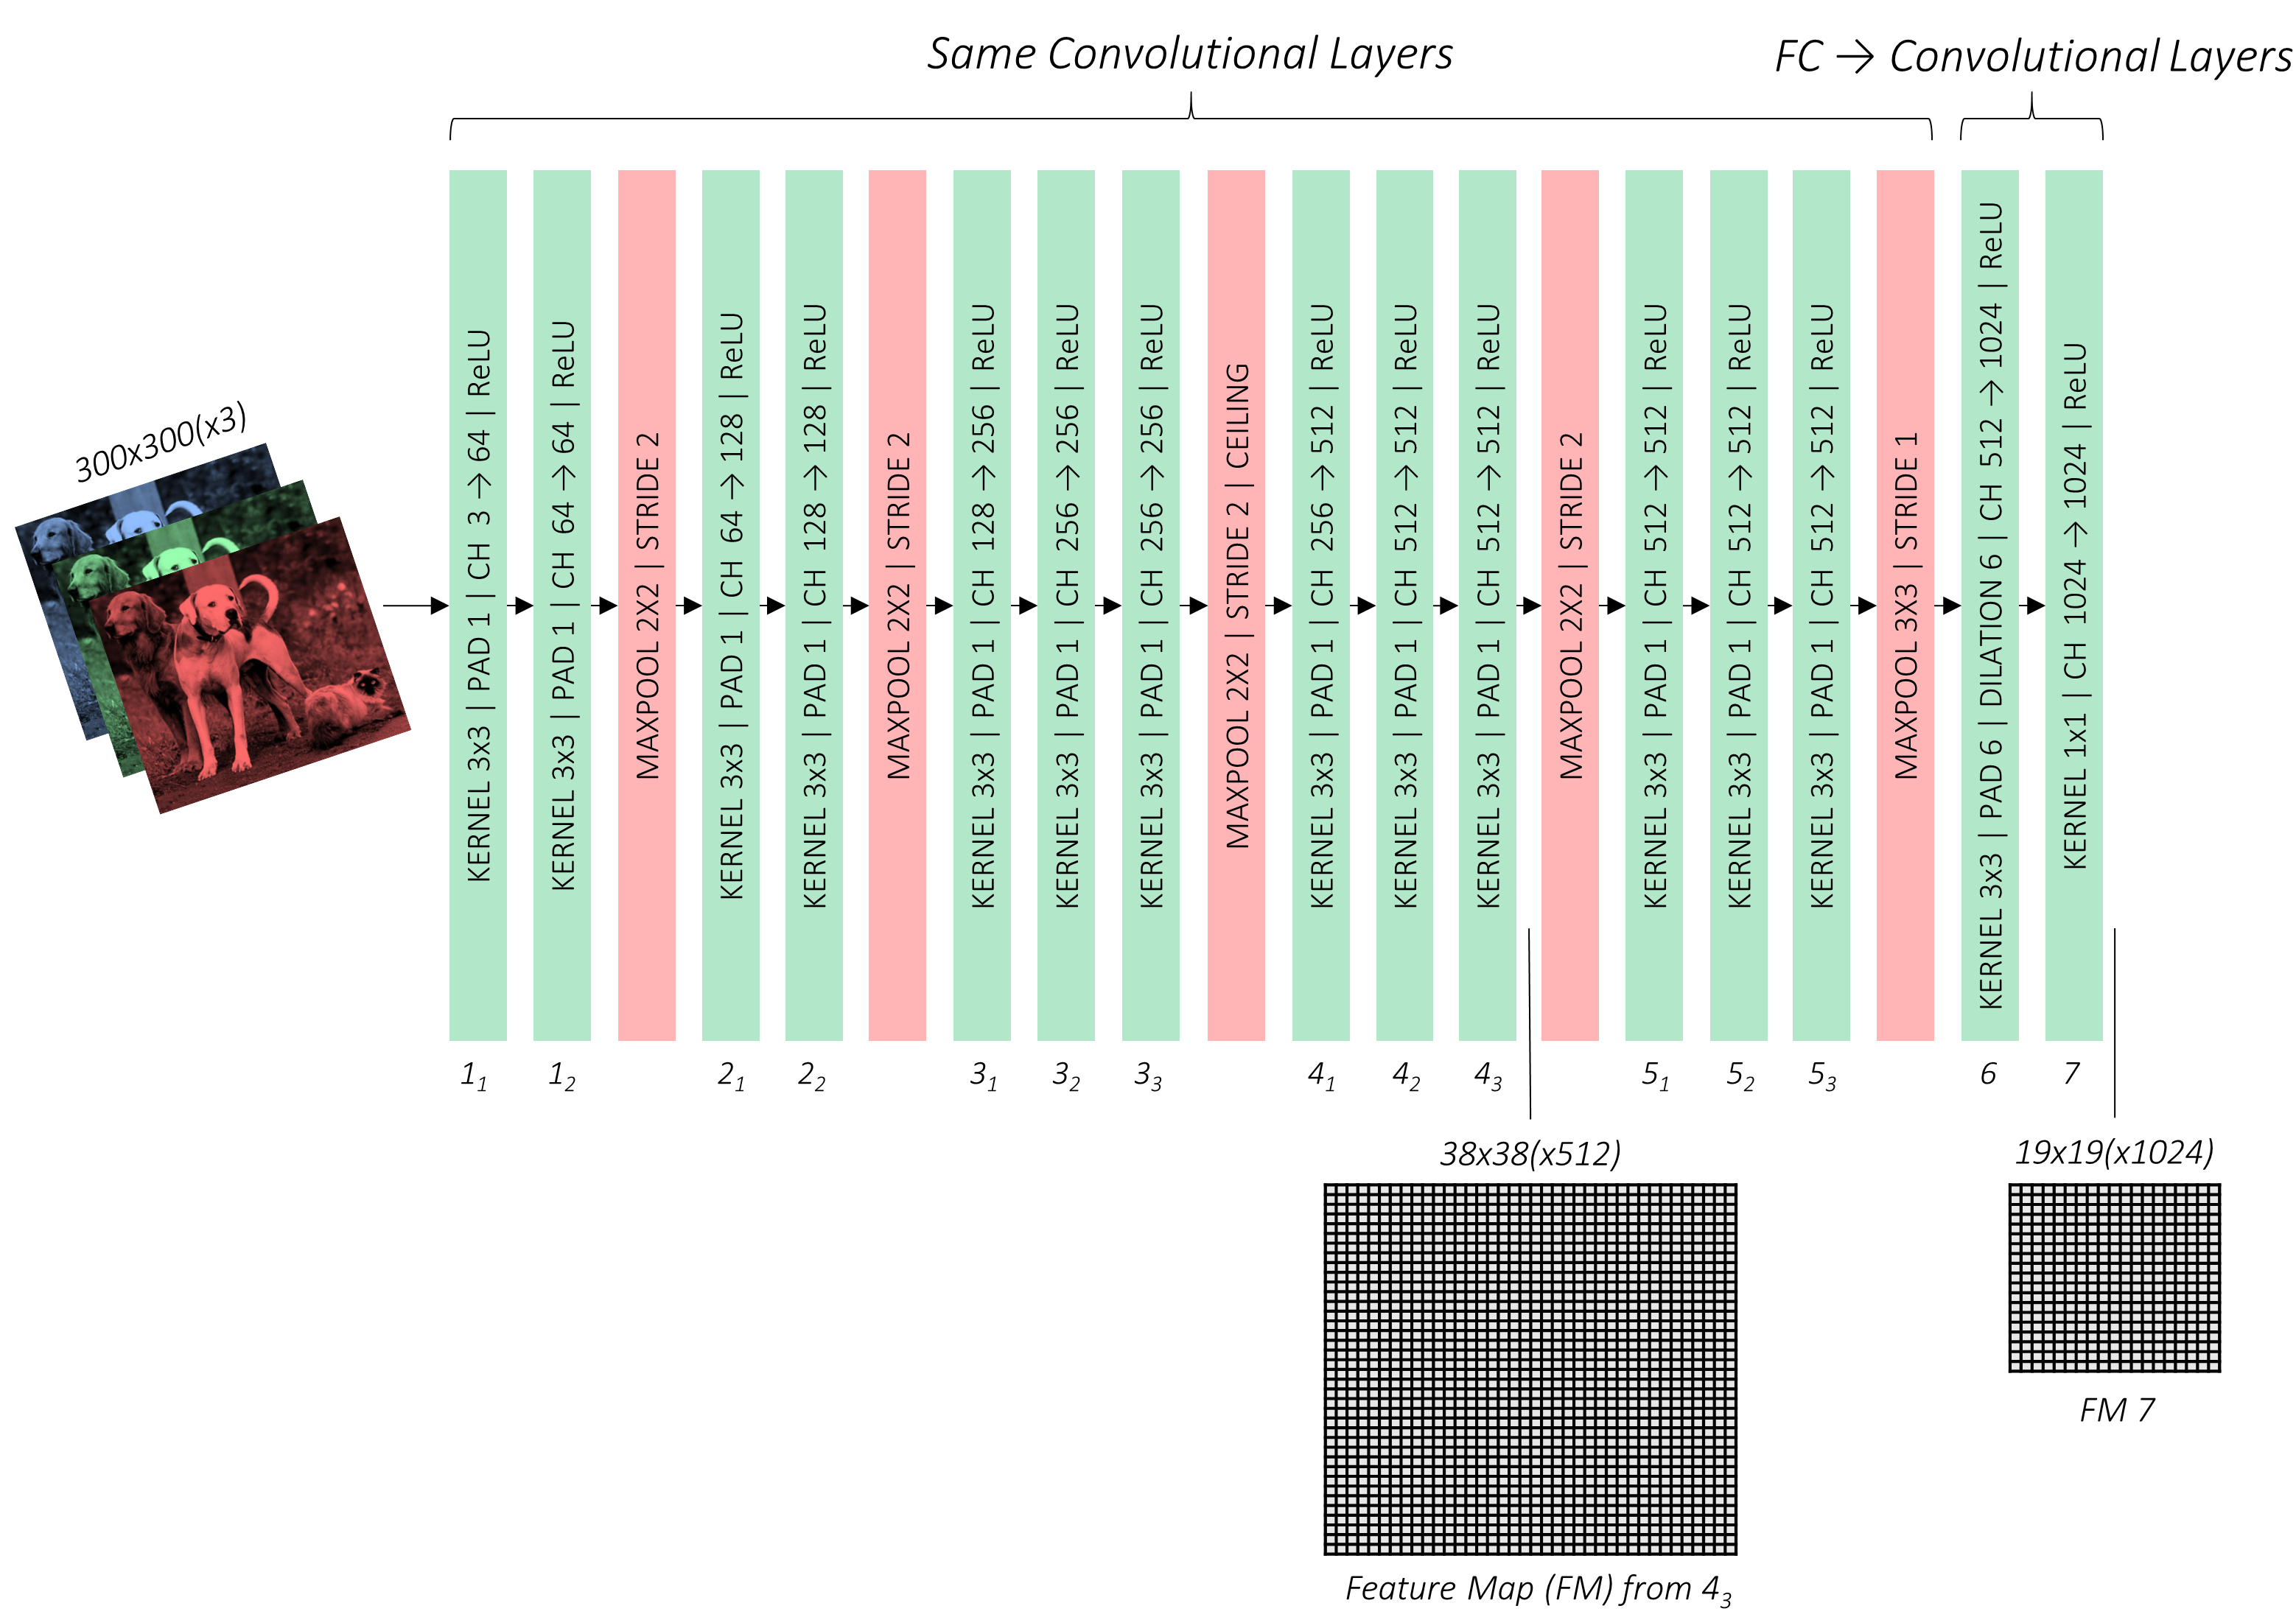

БОНУС. Можно было подойти к разработке модели более тонко. Например, воспользоваться весами `FC6` и `FC7` для инициализации эквивалентных свёрточных слоёв.

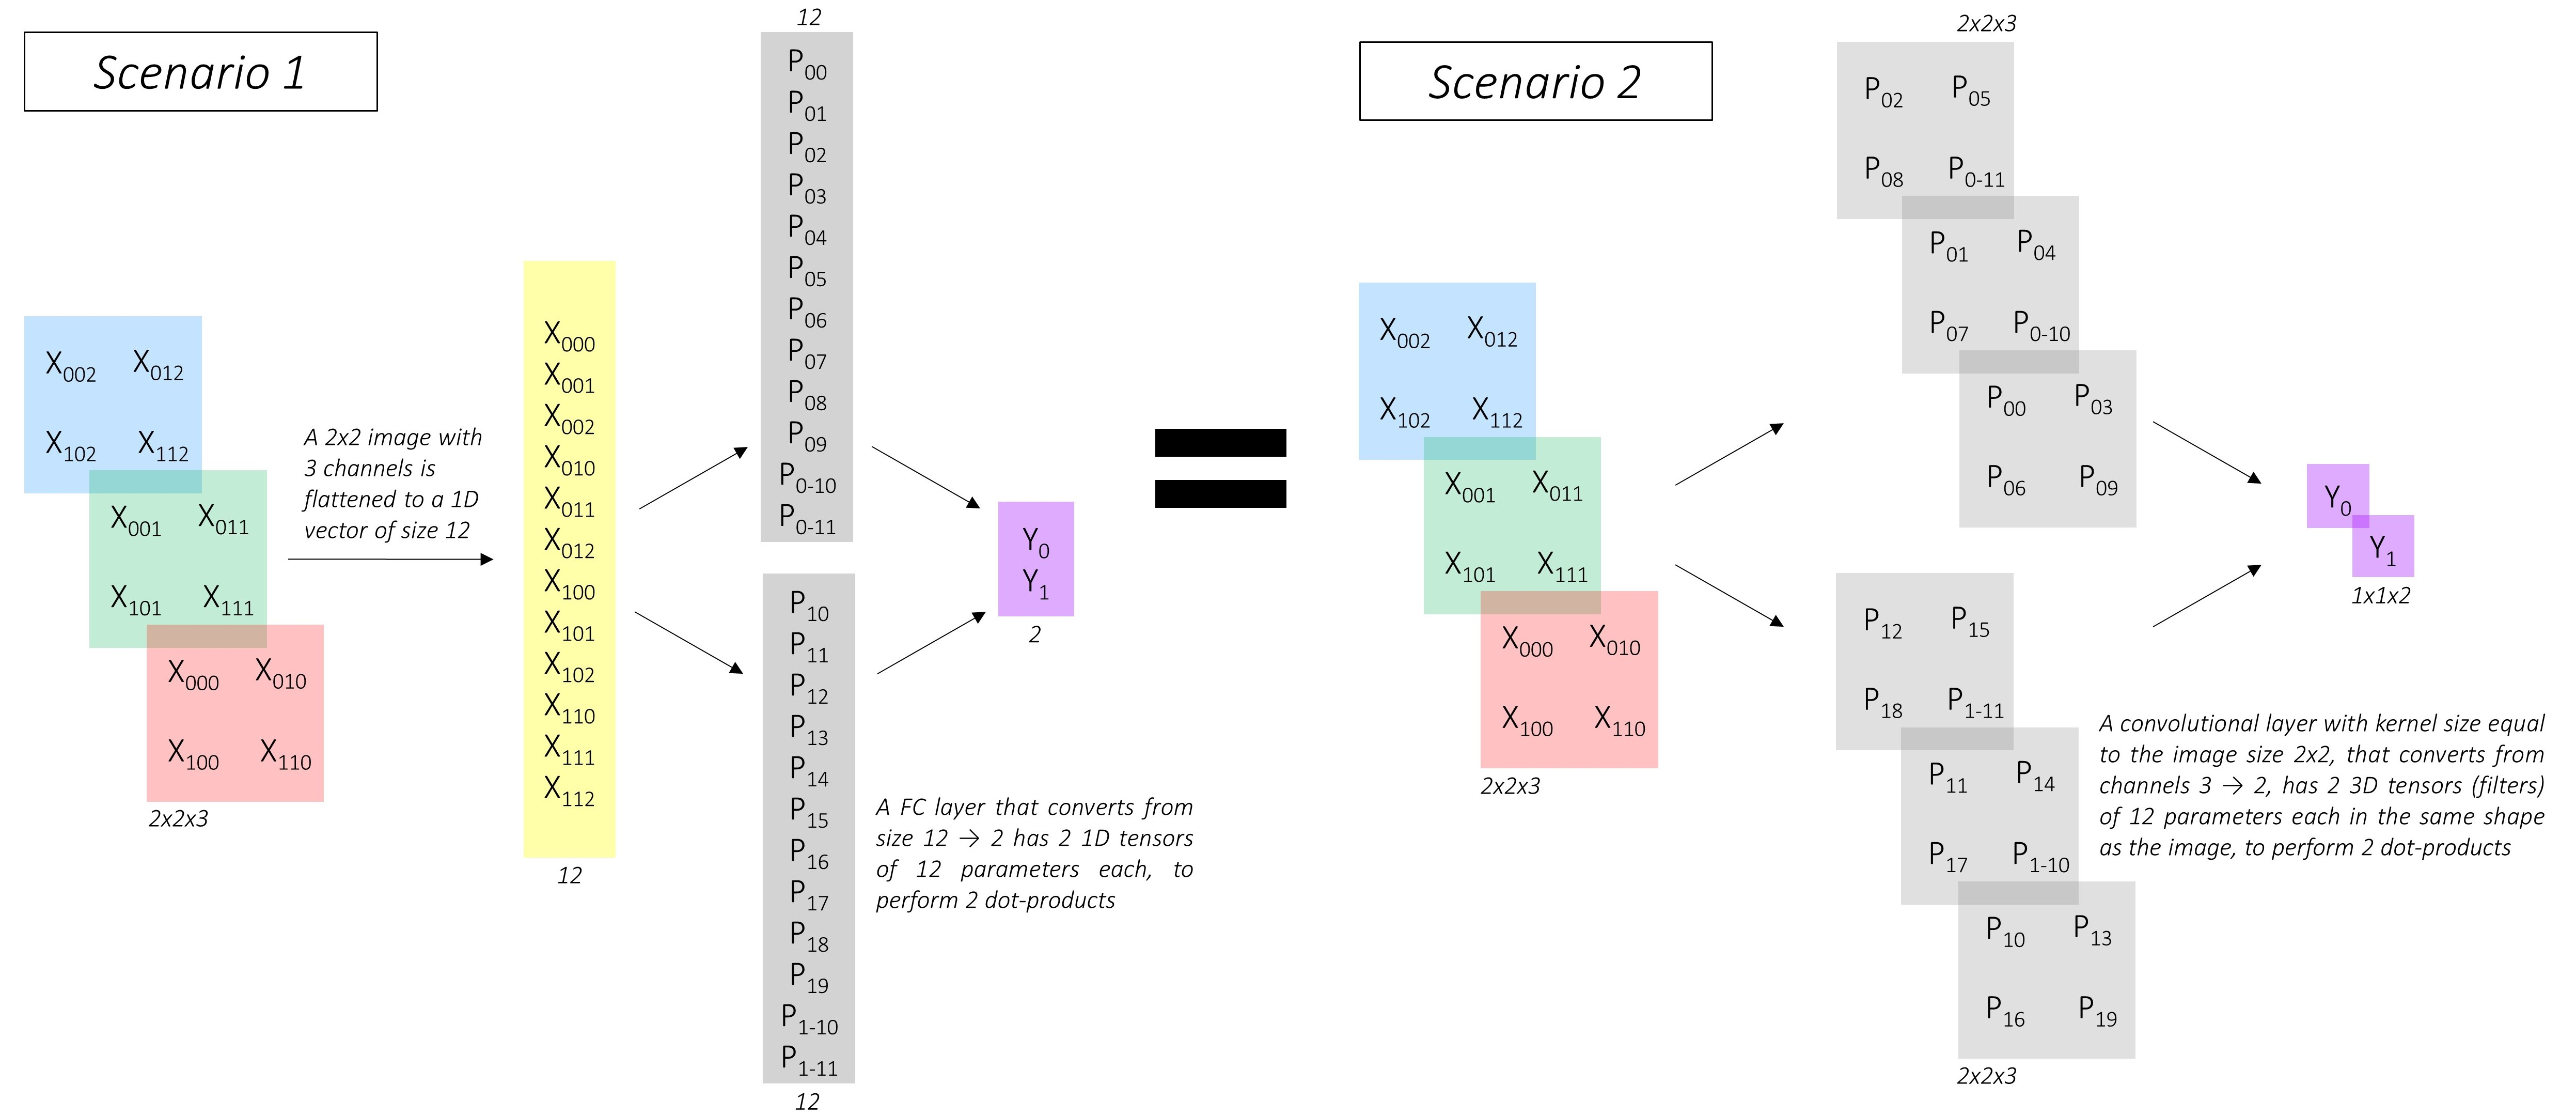

То есть для изображения размера `(H, W)` с `I` каналами применение `FC` слоя с `N` выходами — это **то же самое**, что применение `Conv`-слоя c ядром `(H, W)` и `N` выходами (то есть `N` свёртками толщины `I`).

Число параметров осталось таким же, а значит, когда мы захотели бы взять веса с `ImageNet`, надо было бы сделать просто правильный `reshape`.

Однако просто заменой дело не кончилось. В первоначальной сетке на вход шёл тензор размера `(224, 224, 3)`, и выход `conv5_3` должен быть размера  `(7, 7, 512)`:
 - на `FC6` были размерности `7 × 7 × 512 -> 4096`, а значит, у новой `conv6` `kernel (7, 7)`, толщина свёртки `512` и таких обучаемых ядер `4096` `(4096, 7, 7, 512)`;
 - на `FC7` `4096 -> 4096`, а значит, `conv7` — это `4096` ядер `(1, 1)` с толщиной `4096` `(4096, 1, 1, 4096)`.


Это **очень много параметров**, что вычислительно тяжело.   

Поэтому сделали следующие замены:
 - `conv6`:  `(4096, 7, 7, 512) -> (1024, 3, 3, 512)`;
 - `conv7`: `(4096, 1, 1, 4096) -> (1024, 1, 1, 1024)`.

Сделано это было с помощью `downsampling` (или [`decimation`](https://ru.wikipedia.org/wiki/%D0%94%D0%B5%D1%86%D0%B8%D0%BC%D0%B0%D1%86%D0%B8%D1%8F_(%D0%BE%D0%B1%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%BA%D0%B0_%D1%81%D0%B8%D0%B3%D0%BD%D0%B0%D0%BB%D0%BE%D0%B2))) — то есть при подгрузке весов брали каждое m-е число. При изменении ядер `(7, 7) -> (3, 3)` можно взять `m = 3` и получить тот же `receptive field`, просто с дырками в ядре. Но так как на предыдущем слое размерность больше не падает, авторы взяли `m = 6`.

Обратите внимание на выходы слоев **`conv4_3`** и **`conv_7`** — именно они являются `output`-ами нашего бэкбона. Это первые две «головы» нашего детектора, то есть первые две `feature maps`, на которых мы будем искать объекты.

Теперь давайте посмотрим на код всего этого:

In [ ]:
from torchvision.models import VGG16_Weights
from torchvision        import models

backbone_model    = models.vgg16(weights=VGG16_Weights.DEFAULT)

backbone_model

In [ ]:
base_layers = nn.ModuleList(list(backbone_model.features)[:-1])
base_layers[16].ceil_mode = True

pool5 = nn.MaxPool2d(kernel_size=3, stride=1, padding=1)
conv6 = nn.Conv2d( 512, 1024, kernel_size=3, padding=6, dilation=6)
relu6 = nn.ReLU(inplace=True)
conv7 = nn.Conv2d(1024, 1024, kernel_size=1)
relu7 = nn.ReLU(inplace=True)

nn.init.xavier_uniform_(conv6.weight)
nn.init.zeros_         (conv6  .bias)
nn.init.xavier_uniform_(conv7.weight)
nn.init.zeros_         (conv7  .bias)

base_layers.extend( [pool5, conv6, relu6, conv7, relu7] )

### **Дополнительные свёрточные слои (Auxiliary)**

Добавляем свёрточные слои после `VGG16` и вытаскиваем оттуда ещё `4` карты признаков:

In [ ]:
extra_layers = []

conv8_1  = nn.Conv2d( 1024, 256, kernel_size=1, stride=1           )
relu8_1  = nn.ReLU(inplace=True)
conv8_2  = nn.Conv2d( 256, 512, kernel_size=3, stride=2, padding=1)
relu8_2  = nn.ReLU(inplace=True)
conv9_1  = nn.Conv2d( 512, 128, kernel_size=1, stride=1           )
relu9_1  = nn.ReLU(inplace=True)
conv9_2  = nn.Conv2d( 128, 256, kernel_size=3, stride=2, padding=1)
relu9_2  = nn.ReLU(inplace=True)
conv10_1 = nn.Conv2d( 256, 128, kernel_size=1, stride=1           )
relu10_1 = nn.ReLU(inplace=True)
conv10_2 = nn.Conv2d( 128, 256, kernel_size=3, stride=1           )
relu10_2 = nn.ReLU(inplace=True)
conv11_1 = nn.Conv2d( 256, 128, kernel_size=1, stride=1           )
relu11_1 = nn.ReLU(inplace=True)
conv11_2 = nn.Conv2d( 128, 256, kernel_size=3, stride=1           )
relu11_2 = nn.ReLU(inplace=True)

nn.init.xavier_uniform_(conv8_1 .weight)
nn.init.zeros_         (conv8_1 .bias  )
nn.init.xavier_uniform_(conv8_2 .weight)
nn.init.zeros_         (conv8_2 .bias  )
nn.init.xavier_uniform_(conv9_1 .weight)
nn.init.zeros_         (conv9_1 .bias  )
nn.init.xavier_uniform_(conv9_2 .weight)
nn.init.zeros_         (conv9_2 .bias  )
nn.init.xavier_uniform_(conv10_1.weight)
nn.init.zeros_         (conv10_1.bias  )
nn.init.xavier_uniform_(conv10_2.weight)
nn.init.zeros_         (conv10_2.bias  )
nn.init.xavier_uniform_(conv11_1.weight)
nn.init.zeros_         (conv11_1.bias  )
nn.init.xavier_uniform_(conv11_2.weight)
nn.init.zeros_         (conv11_2.bias  )

extra_layers = nn.ModuleList( [conv8_1, relu8_1, conv8_2, relu8_2, conv9_1, relu9_1, conv9_2, relu9_2, conv10_1, relu10_1, conv10_2, relu10_2, conv11_1, relu11_1, conv11_2, relu11_2] )

In [ ]:
total_layers = base_layers + extra_layers
total_layers

<img src="...
" alt="drawing" width="1000"/>

### **Prior boxes**

Prior Boxes — это множество некоторых базовых прямоугольников, задача регрессии решается относительно этих прямоугольников, мы учимся предсказывать поправки к базовым прямоугольникам. Результирующие прямоугольники есть базовые прямоугольники плюс некоторые поправки, которые предсказывает модель.

**Особенности Prior Boxes**

- Каждый `prior box` связан с отдельным пространственным элементом каждой из карт признаков `(conv4_3, conv7, conv8_2, conv9_2, conv10_2, conv11_2)`.
- Каждый `prior box` имеет параметр `s — scale`, это значит, что площадь якоря будет `s^2×S_fm`. Например, на первой карте признаков `fm — conv4_3` у всех якорей `scale` `0.1` (то есть `10%` от размеров `fm`), самый большой `scale` на последнем слое `conv11_2` — `0.9`, но там размерность `feature map` уже `(1, 1)`, а значит, `receptive field` такого представления — ВСЯ первоначальная картинка. Отсюда прямо следует что **чем выше номер головы**, тем **более крупные объекты** там детектируются.
- Каждый `prior box` также характеризутеся `aspect ratio`. В каждом пространственном элементе `feature map` будет несколько `prior box` c одинаковым `scale` (кроме одного), но с разным `aspect ratio` (квадрат `1:1`, горизонтальный прямоугольник — `1:2`, `1:3` и вертикальный прямоугольник — `2:1`, `3:1`).

**Важный note:** `prior boxes` желательно чётко подбирать под вашу задачу. Если вы будете детектировать гуляющих людей, вам не понадобятся вертикальные прямоугольники. Тонкая настройка прямоугольников под свою задачу позволит получить модель, которая быстрее выучится и будет точнее локализовать объекты.

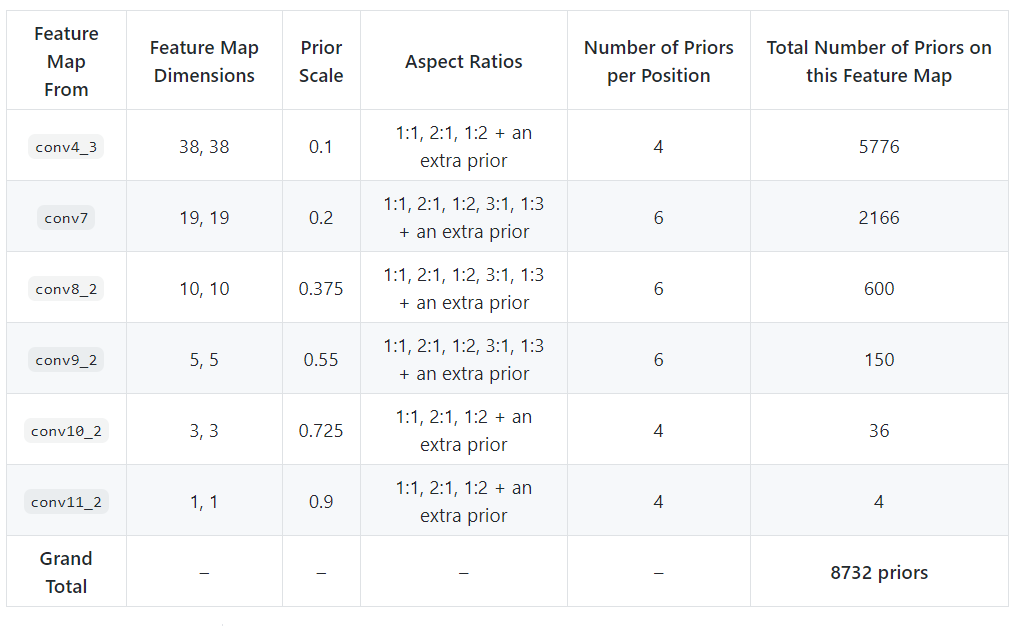

Итак, `prior box` определяется своими параметрами `scale` и `aspect ratio`, инициализируется с центром в каждой точке `feature map` и обрезается, если вылезает за край изображения. Для того же слоя `conv9_2` они выглядят так:

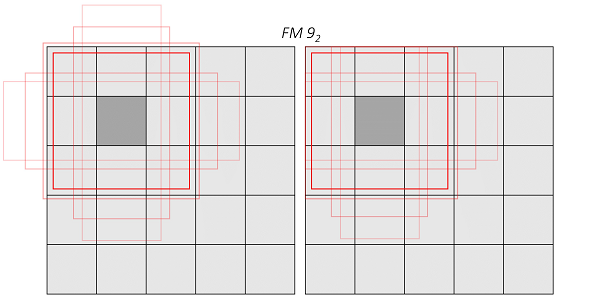

`prior boxes` явно не входят в модель, и на `prediction`-слое ядра не ходят по заранее очерченным границам, которые якори задают (как можно было бы сделать, например). От якорей, по сути, нужны только их координаты, которые будут уточняться в `localization prediction`. В создании представлений `prior boxes` не участвуют, мы только **закрепили**, что определённое представление (`N`-е) соответствует определённому якорю. И в процессе обучения оно **само выучитывается** тому, чтобы наилучшим образом соответствовать объекту в области якоря.

Поканально в `prediction convolution` результатах соответствие якорям выглядит так:


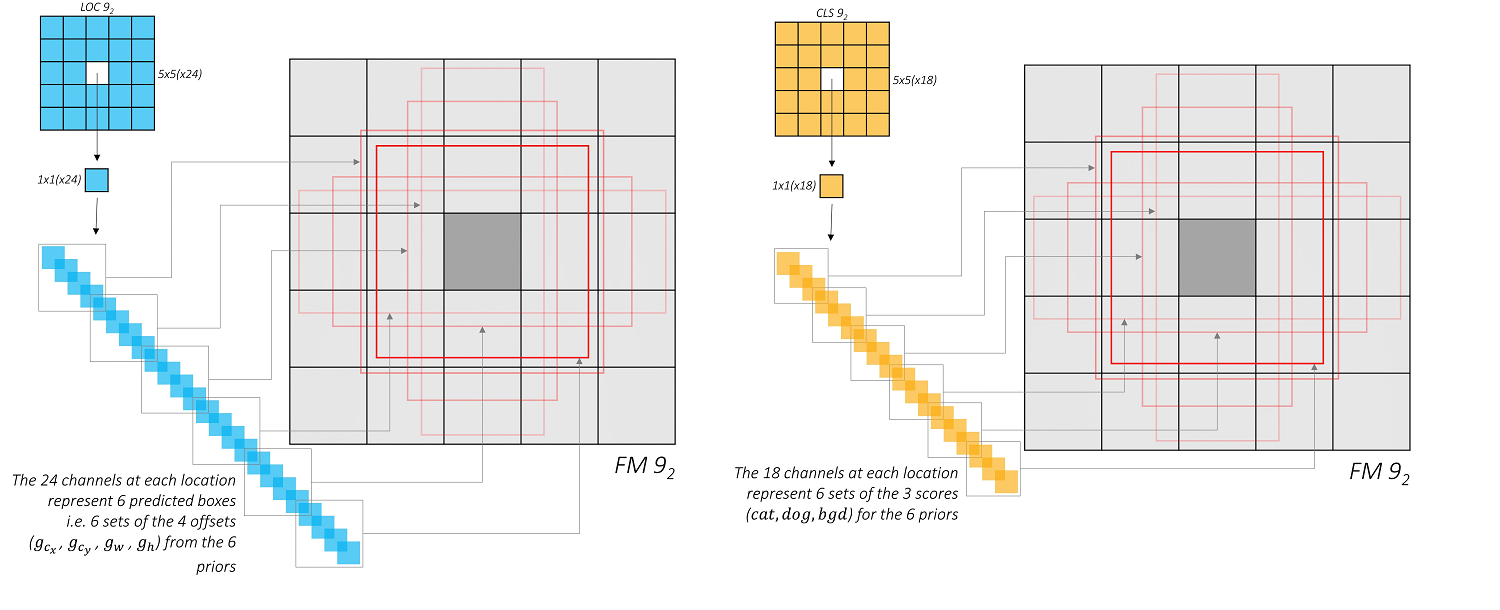

Дальше остаётся эти представления только reshape (изменить размерности) в нужную форму (которую мы сможем понять и агрегировать для якорей их результаты).

### **Дополнительные свёрточные слои (Prediction)**

In [ ]:
used_layer_id_s       = [21, 33, 37, 41, 45, 49]

In [ ]:
out_channels_s = [ total_layers[i].out_channels for i in used_layer_id_s ]
num_bboxes_s = [2, 2, 2, 2, 2, 2]
num_labels   = 2

conf_layers, loc_layers = [], []
for i, j in enumerate(used_layer_id_s):
    conf_layer = nn.Conv2d( total_layers[j].out_channels, num_bboxes_s[i] * num_labels, kernel_size=3, padding=1)
    loc_layer  = nn.Conv2d( total_layers[j].out_channels, num_bboxes_s[i] * 4         , kernel_size=3, padding=1)

    nn.init.xavier_uniform_(conf_layer.weight)
    nn.init.zeros_         (conf_layer  .bias)
    nn.init.xavier_uniform_(loc_layer .weight)
    nn.init.zeros_         (loc_layer   .bias)

    conf_layers += [conf_layer]
    loc_layers  += [loc_layer ]

    conf_layers = nn.ModuleList(conf_layers)
    loc_layers  = nn.ModuleList(loc_layers )

### **Результирующая модель**

In [ ]:
!pip install torchview

In [ ]:
from torchvision.models import VGG16_Weights
from torchvision        import models
from torchview          import draw_graph

import torch.nn.init as init

class L2Norm(nn.Module):
    def __init__(self, n_channels, scale):
        super(L2Norm, self).__init__()
        self.n_channels = n_channels
        self.gamma      = scale or None
        self.eps        = 1e-10
        self.weight     = nn.Parameter(torch.Tensor(self.n_channels))
        self.reset_parameters()

    def reset_parameters(self):
        init.constant_(self.weight, self.gamma)

    def forward(self, x):
        norm = torch.sqrt(x.pow(2).sum(dim=1, keepdim=True)) + self.eps
        x = torch.div(x, norm)
        x = self.weight.unsqueeze(0).unsqueeze(2).unsqueeze(3).expand_as(x) * x
        return x

class SSD_VGG16(nn.Module):
    def __init__(self, num_bboxes_s, num_labels = 3):
        super().__init__()

        self.num_bboxes_s = num_bboxes_s
        self.num_labels   = num_labels

        use_bn = True

        self.used_layer_id_s = [21, 34, 40, 46, 52, 58] if use_bn else [21, 33, 37, 41, 45, 49]
        self.norm_layer      = L2Norm(512, 20)

        base_layers       = self._build_base_layers (use_bn)
        extra_layers      = self._build_extra_layers(use_bn)
        self.total_layers = base_layers + extra_layers

        #print( self.total_layers )

        self.conf_layers, self.loc_layers = self._build_conf_loc_layers()

    def _build_base_layers(self, use_bn):
        backbone_model    = models.vgg16(weights=VGG16_Weights.DEFAULT)  #False

        base_layers = nn.ModuleList(list(backbone_model.features)[:-1])
        base_layers[16].ceil_mode = True

        pool5 = nn.MaxPool2d(kernel_size=3, stride=1, padding=1)
        conv6 = nn.Conv2d( 512, 1024, kernel_size=3, padding=6, dilation=6)
        norm6 = nn.BatchNorm2d(1024)
        relu6 = nn.ReLU(inplace=True)
        conv7 = nn.Conv2d(1024, 1024, kernel_size=1)
        norm7 = nn.BatchNorm2d(1024)
        relu7 = nn.ReLU(inplace=True)

        nn.init.xavier_uniform_(conv6.weight)
        nn.init.zeros_         (conv6  .bias)
        nn.init.xavier_uniform_(conv7.weight)
        nn.init.zeros_         (conv7  .bias)

        if use_bn:
            base_layers.extend( [pool5, conv6, norm6, relu6, conv7, norm7, relu7] )
        else:
            base_layers.extend( [pool5, conv6, relu6, conv7, relu7] )

        return base_layers

    def _build_extra_layers(self, use_bn):
        extra_layers = []

        conv8_1  = nn.Conv2d( 1024, 256, kernel_size=1, stride=1           )
        norm8_1  = nn.BatchNorm2d(256)
        relu8_1  = nn.ReLU(inplace=True)
        conv8_2  = nn.Conv2d( 256, 512, kernel_size=3, stride=2, padding=1)
        norm8_2  = nn.BatchNorm2d(512)
        relu8_2  = nn.ReLU(inplace=True)
        conv9_1  = nn.Conv2d( 512, 128, kernel_size=1, stride=1           )
        norm9_1  = nn.BatchNorm2d(128)
        relu9_1  = nn.ReLU(inplace=True)
        conv9_2  = nn.Conv2d( 128, 256, kernel_size=3, stride=2, padding=1)
        norm9_2  = nn.BatchNorm2d(256)
        relu9_2  = nn.ReLU(inplace=True)
        conv10_1 = nn.Conv2d( 256, 128, kernel_size=1, stride=1           )
        norm10_1  = nn.BatchNorm2d(128)
        relu10_1 = nn.ReLU(inplace=True)
        conv10_2 = nn.Conv2d( 128, 256, kernel_size=3, stride=1           )
        norm10_2 = nn.BatchNorm2d(256)
        relu10_2 = nn.ReLU(inplace=True)
        conv11_1 = nn.Conv2d( 256, 128, kernel_size=1                     )
        norm11_1 = nn.BatchNorm2d(128)
        relu11_1 = nn.ReLU(inplace=True)
        conv11_2 = nn.Conv2d( 128, 256, kernel_size=3, stride=1           )
        norm11_2 = nn.BatchNorm2d(256)
        relu11_2 = nn.ReLU(inplace=True)

        nn.init.xavier_uniform_(conv8_1 .weight)
        nn.init.zeros_         (conv8_1 .bias  )
        nn.init.xavier_uniform_(conv8_2 .weight)
        nn.init.zeros_         (conv8_2 .bias  )
        nn.init.xavier_uniform_(conv9_1 .weight)
        nn.init.zeros_         (conv9_1 .bias  )
        nn.init.xavier_uniform_(conv9_2 .weight)
        nn.init.zeros_         (conv9_2 .bias  )
        nn.init.xavier_uniform_(conv10_1.weight)
        nn.init.zeros_         (conv10_1.bias  )
        nn.init.xavier_uniform_(conv10_2.weight)
        nn.init.zeros_         (conv10_2.bias  )
        nn.init.xavier_uniform_(conv11_1.weight)
        nn.init.zeros_         (conv11_1.bias  )
        nn.init.xavier_uniform_(conv11_2.weight)
        nn.init.zeros_         (conv11_2.bias  )

        extra_layers = None
        if use_bn:
            extra_layers = nn.ModuleList( [
             conv8_1 , norm8_1 , relu8_1 ,
             conv8_2 , norm8_2 , relu8_2 ,
             conv9_1 , norm9_1 , relu9_1 ,
             conv9_2 , norm9_2 , relu9_2 ,
             conv10_1, norm10_1, relu10_1,
             conv10_2, norm10_2, relu10_2,
             conv11_1, norm11_1, relu11_1,
             conv11_2, norm11_2, relu11_2
            ] )
        else:
            extra_layers = nn.ModuleList( [
             conv8_1 , relu8_1 ,
             conv8_2 , relu8_2 ,
             conv9_1 , relu9_1 ,
             conv9_2 , relu9_2 ,
             conv10_1, relu10_1,
             conv10_2, relu10_2,
             conv11_1, relu11_1,
             conv11_2, relu11_2
            ] )
        return extra_layers

    def _build_conf_loc_layers(self):
        out_channels_s = [ self.total_layers[i].out_channels for i in self.used_layer_id_s ]

        conf_layers, loc_layers = [], []
        for i, j in enumerate(self.used_layer_id_s):
            conf_layer = nn.Conv2d( self.total_layers[j].out_channels, self.num_bboxes_s[i] * self.num_labels, kernel_size=3, padding=1)
            loc_layer  = nn.Conv2d( self.total_layers[j].out_channels, self.num_bboxes_s[i] * 4              , kernel_size=3, padding=1)

            nn.init.xavier_uniform_(conf_layer.weight)
            nn.init.zeros_         (conf_layer  .bias)
            nn.init.xavier_uniform_(loc_layer .weight)
            nn.init.zeros_         (loc_layer   .bias)

            conf_layers += [conf_layer]
            loc_layers  += [loc_layer ]

        conf_layers = nn.ModuleList(conf_layers)
        loc_layers  = nn.ModuleList(loc_layers )

        return conf_layers, loc_layers

    def forward(self, x, verbose=False):
        source_s, loc_s, conf_s = [], [], []

        for i, current_layer in enumerate(self.total_layers, -1):
            x = current_layer(x)
            if i in self.used_layer_id_s:
                if i == 21:
                    s = self.norm_layer(x)
                else:
                    s = x
                source_s.append(s)
        for s, l, c in zip(source_s, self.loc_layers, self.conf_layers):
            conf_s.append(c(s).permute(0, 2, 3, 1).contiguous())
            loc_s .append(l(s).permute(0, 2, 3, 1).contiguous())
        conf_s = torch.cat([o.view(o.size(0), -1) for o in conf_s], 1)
        loc_s  = torch.cat([o.view(o.size(0), -1) for o in loc_s ], 1)

        conf_s = conf_s.view(conf_s.size(0), -1, self.num_labels)
        loc_s  = loc_s .view(loc_s .size(0), -1, 4              )

        return loc_s, conf_s

In [ ]:
num_bboxes_s = [2, 2, 2, 2, 2, 2]

model = SSD_VGG16(num_bboxes_s, 2)
model.eval()

input_data  = torch.randn(1,3,360, 640, dtype=torch.float, requires_grad=False)
output_locs, output_confs = model( input_data )

model_graph  = draw_graph(model, input_size=(1,3,360,640), expand_nested=True)
visual_graph = model_graph.visual_graph
visual_graph

### 4. Функция потерь MultiBox Loss

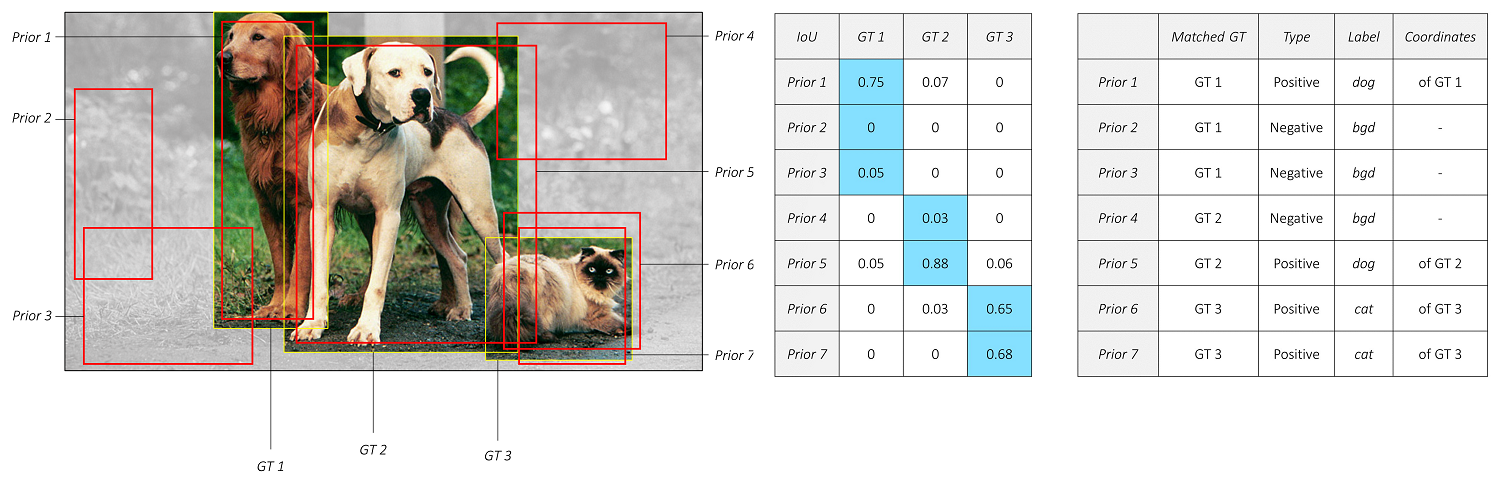

**Алгоритм обработки боксов:**

- считаем [`intersection over union (IoU)`](http://d2l.ai/chapter_computer-vision/anchor.html#intersection-over-union-iou)  между `groundtruth (GT)` разметкой на текущем изображении и всех (да, `8732`) `prior boxes`;
- решаем задачу сопоставления между собой `GT` прямоугольников и `prior boxes` ([задача о назначениях](https://ru.wikipedia.org/wiki/%D0%97%D0%B0%D0%B4%D0%B0%D1%87%D0%B0_%D0%BE_%D0%BD%D0%B0%D0%B7%D0%BD%D0%B0%D1%87%D0%B5%D0%BD%D0%B8%D1%8F%D1%85)), `prior box` с `IoU` выше некоторого порога (например, `0.5`) считается **positive**, иначе **negative**.

**Localization loss**

Для всех позитивных `prior boxes` мы имеем `GT`-разметку, для негативных не имеем таких примеров. Поэтому локализационная часть лосса работает только для `positive`-примеров — уточняет их координаты с помощью [`Smooth L1`](https://pytorch.org/docs/stable/generated/torch.nn.SmoothL1Loss.html) лосса (итоговый лосс — средний по всем `positive`-примерам). `That's all`.

**Confidence loss**

Разметка по классам у нас есть для каждого предсказания — если он `negative`, то класс `background`. Совсем выкидывать их из обучения нельзя — сеть должна понимать, как выглядит фон, но и используя их все, мы значительно перевесим настоящие объекты. Действовать надо аккуратно.

Решение в целом очевидно — ограничим число негативных примеров, на которых будем обучаться. Надо только выбрать самые лучшие негативные примеры. Как? С помощью **Hard Negative Mining** — выбирая только те примеры, на которых целевой [`CrossEntropy Loss`](https://pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html) будет наибольшим. В статье предлагается эвристика — брать `negative`-примеров в `3` раза больше, чем `positive`.

То есть мы считаем для каждого предсказания `CrossEntropy Loss`, для негативных выбираем топ, позитивные берём все, далее нормируем на число позитивных примеров — и вот он готов.

Между собой лоссы можно соотносить по важности с помощью гиперпараметра, но в статье он равен 1, и части равнозначны.

**Немножко неприятного про координаты для регрессии**

Участовать в регрессии будут `GT`-разметка (очевидно) и наши текущие `localization`-предсказания. Но сделаны и обучены эти предсказания должны быть относительно своего `prior box` (помним же, что в `localization prediction` каждая часть выхода соответствует `prior box`). Как это делается?

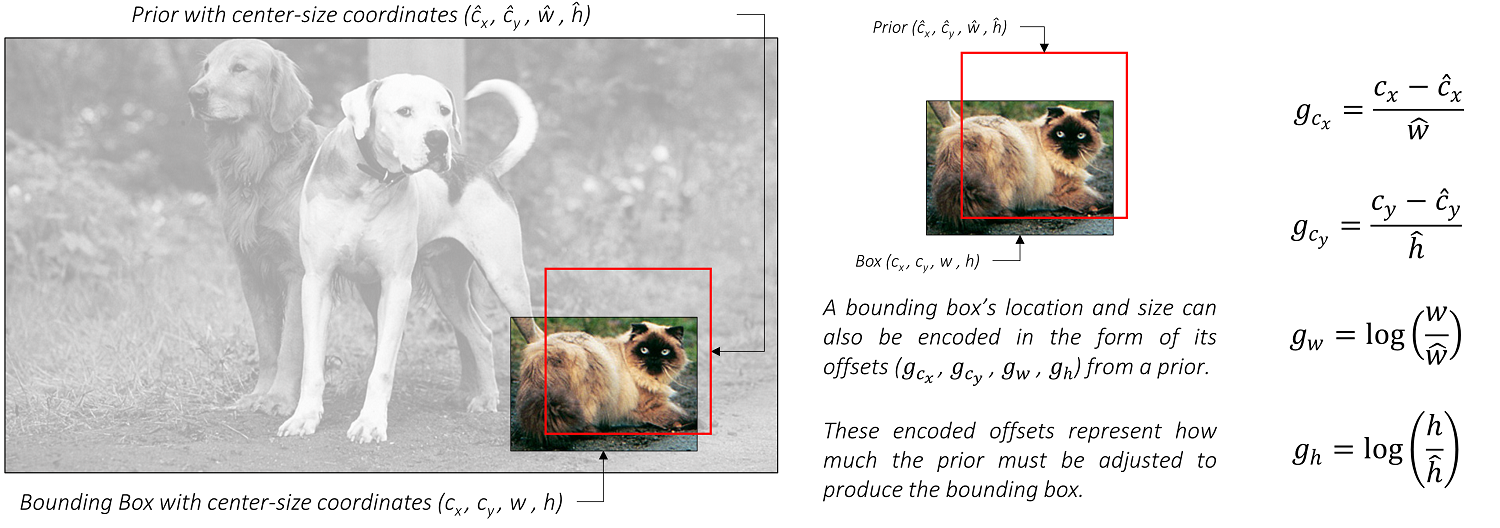

**Пояснения по формулам**

Мы пытаемся предсказывать боксы разных размеров, наши поправки не должны зависеть от масштаба. Важность координат центра и размеров бокса разная, поэтому мы используем разные нормировки.

1. Поправки к координатам центра мы нормируем на размер соответствующего `prior box`.
2. Поправки к размерам мы нормируем на размер бокса и берём функцию логарифма.



In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Define the range of x values close to one
x_values = np.linspace(0.6, 1.4, 400)

# Calculate the natural logarithm (log base e) of x values
log_values  = np.log(x_values)
line_values = x_values - 1
# Create the plot
plt.figure(figsize=(8, 6))
plt.plot(x_values, log_values , label='y = log(x)', color='blue')
plt.plot(x_values, line_values, label='y = x - 1' , color='red')
# Highlight the point where x = 1
plt.scatter([1], [0], color='red', zorder=5)
plt.axvline(x=1, color='gray', linestyle='--', linewidth=0.8)
plt.axhline(y=0, color='gray', linestyle='--', linewidth=0.8)

# Add labels and title
plt.xlabel('x')
plt.ylabel('log(x)')
plt.title('Сравнение разных нормировок для поправок к размерам бокса')
plt.legend()

# Show the plot
plt.grid(True)
plt.show()

In [ ]:
def encode(matched, priors, variances):
    """Encode the variances from the priorbox layers into the ground truth boxes
    we have matched (based on jaccard overlap) with the prior boxes.
    Args:
        matched: (tensor) Coords of ground truth for each prior in point-form
            Shape: [num_priors, 4].
        priors: (tensor) Prior boxes in center-offset form
            Shape: [num_priors,4].
        variances: (list[float]) Variances of priorboxes
    Return:
        encoded boxes (tensor), Shape: [num_priors, 4]
    """
    # dist b/t match center and prior's center
    g_cxcy = (matched[:, :2] + matched[:, 2:])/2 - priors[:, :2]
    # encode variance
    g_cxcy /= (variances[0] * priors[:, 2:])
    # match wh / prior wh
    g_wh = (matched[:, 2:] - matched[:, :2]) / priors[:, 2:]
    g_wh = torch.log(g_wh) / variances[1]
    # return target for smooth_l1_loss
    return torch.cat([g_cxcy, g_wh], 1)  # [num_priors,4]

def decode(loc, priors, variances):
    """Decode locations from predictions using priors to undo
    the encoding we did for offset regression at train time.
    Args:
        loc (tensor): location predictions for loc layers,
            Shape: [num_priors,4]
        priors (tensor): Prior boxes in center-offset form.
            Shape: [num_priors,4].
        variances: (list[float]) Variances of priorboxes
    Return:
        decoded bounding box predictions
    """
    boxes = torch.cat(( priors[:, :2] + loc[:, :2] * variances[0] * priors[:, 2:], priors[:, 2:] * torch.exp(loc[:, 2:] * variances[1])), 1)
    boxes[:, :2] -= boxes[:, 2:] / 2
    boxes[:, 2:] += boxes[:, :2]
    return boxes

Вот эти четыре отступа `(g_c_x, g_c_y, g_w, g_h)` — как раз то, что мы будем использовать в регрессии. Обратите внимание, что они нормированы по размеру якоря, это логично — один и тот же размер отступа в зависимости от размера якоря будет иметь разную значимость.

Скачаем дополнительный набор исходных кодов для решения задачи.

|  Файл | Назначение |
| ------------------ | ---------- |
| voc_dataset.py     | Файл содержит класс `VOCDetection`, экземпляр этого класса используется для загрузки данных в формате `VOC`           |
| voc_dataloader.py  | Файл содержит две функции `get_train_dataloader` и `get_test_dataloader`, которые создают два загрузчика данных      |
| prior_boxes.py     | Файл содержит набор полезных функций для работы с `ptior_boxes`, например их создание и решение задачи сопоставления |
| mulibox_loss.py    | Файл содержит класс `MultiBoxLoss`, экземпляр этого класса используется в качестве функции потерь                    |

In [ ]:
!git clone https://github.com/SergeyMalashenko/ObjectDetectionProblemFromScratch.git utils

In [ ]:
from utils.prior_boxes import prior_boxes, match, encode, decode

class MultiBoxLoss(nn.Module):
    """SSD Weighted Loss Function
    Compute Targets:
        1) Produce Confidence Target Indices by matching  ground truth boxes
           with (default) 'priorboxes' that have jaccard index > threshold parameter
           (default threshold: 0.5).
        2) Produce localization target by 'encoding' variance into offsets of ground
           truth boxes and their matched  'priorboxes'.
        3) Hard negative mining to filter the excessive number of negative examples
           that comes with using a large number of default bounding boxes.
           (default negative:positive ratio 3:1)
    Objective Loss:
        L(x,c,l,g) = (Lconf(x, c) + αLloc(x,l,g)) / N
        Where, Lconf is the CrossEntropy Loss and Lloc is the SmoothL1 Loss
        weighted by α which is set to 1 by cross val.
        Args:
            c: class confidences,
            l: predicted boxes,
            g: ground truth boxes
            N: number of matched default boxes
        See: https://arxiv.org/pdf/1512.02325.pdf for more details.
    """

    def __init__(self, overlap_threshold, neg_pos_ratio, variance):
        super(MultiBoxLoss, self).__init__()
        self.threshold     = overlap_threshold
        self.neg_pos_ratio = neg_pos_ratio
        self.variance      = variance

    def forward(self, predictions, targets):
        """Multibox Loss
        Args:
            predictions (tuple): A tuple containing loc preds, conf preds,
            and prior boxes from SSD net.
                conf shape: torch.size(batch_size,num_priors,num_classes)
                loc shape: torch.size(batch_size,num_priors,4)
                priors shape: torch.size(num_priors,4)

            targets (tensor): Ground truth boxes and labels for a batch,
                shape: [batch_size,num_objs,5] (last idx is the label).
        """
        loc_data, conf_data, priors = predictions
        gt_label_s, gt_box_s = targets

        device = loc_data.device

        batch_size  = loc_data .size( 0)
        num_priors  = loc_data .size( 1)
        num_classes = conf_data.size(-1)

        # match priors (default boxes) and ground truth boxes
        loc_t  = torch.zeros(batch_size, num_priors, 4, device=device).float()
        conf_t = torch.zeros(batch_size, num_priors   , device=device).long ()

        neg_pos_ratio = self.neg_pos_ratio
        threshold     = self.threshold
        variance      = self.variance
        #Решаем задачу соответствия между GT-боксами и предсказанными боксами
        for idx in range(batch_size):
            loc_t[idx], conf_t[idx] = match(threshold, gt_box_s[idx], priors, variance, gt_label_s[idx])

        pos = conf_t > 0
        num_pos = pos.sum(dim=1, keepdim=True)

        # Вычисляем Localization Loss (Smooth L1)
        # Shape: [batch, num_priors, 4]
        loc_p = loc_data[pos].view(-1, 4)
        loc_t = loc_t   [pos].view(-1, 4)
        loss_l = F.smooth_l1_loss(loc_p, loc_t, reduction='sum')

        # Вычисляем Classification Loss
        loss_c = F.cross_entropy(conf_data.view(-1, num_classes), conf_t.view(-1), reduction='none')
        loss_c = loss_c.view(batch_size, num_priors)

        # Filter out the negative samples and reduce the loss by sum
        loss_c_pos = loss_c[pos].sum()

        # Hard negative mining
        num_neg = torch.clamp(neg_pos_ratio * num_pos, max=pos.size(1) - 1)
        loss_c_neg = loss_c * ~pos
        loss_c_neg, _ = loss_c_neg.sort(1, descending=True)
        neg_mask = torch.zeros_like(loss_c_neg)
        neg_mask[torch.arange(batch_size), num_neg.view(-1)] = 1.
        neg_mask = 1 - neg_mask.cumsum(-1)
        loss_c_neg = (loss_c_neg * neg_mask).sum()

        # Finally we normalize the losses by the number of positives
        N = num_pos.sum()
        loss_l = loss_l / N
        loss_c = (loss_c_pos + loss_c_neg) / N

        return loss_l, loss_c

### 5. Тренировка модели

Для демонстрации работы подхода `SSD` мы настроим нашу модель на задачу детектирования автомобилей.

Набор данных состоит из `1528` изображений в разрешении `640 × 360` (тренировочная выборка — 1464 изображения, тестовая выборка — 64 изображения) в формате `VOC`.

Набор имеет следующую структуру:

|  Директория      | Содержимое |
| ---------------- | ---------- |
| Annotations      | Папка содержит разметку в виде набора файлов в формате `XML`, каждый файл содержит информацию об объектах (класс объекта, рамка объекта `xmin,ymin,xmax,ymax`)    |
| ImageSets/Main   | Папка содержит два текстовых файла с распределением данных на тренировочную `trainval.txt` и тестовую выборки `test.txt` |
| JPEGImages       | Папка содержит изображения в `JPEG`-формате |

Пример изображения из набора данных

![Image](sample.jpg)

Пример фрагмента разметки данных из набора данных

```
...
<size>
    <width>1280</width>
    <height>720</height>
    <depth>3</depth>
</size>
<object>
    <name>car</name>
    <bndbox>
        <xmin>807</xmin>
        <ymin>30</ymin>
        <xmax>1101</xmax>
        <ymax>356</ymax>
    </bndbox>
</object>
...
```


In [ ]:
!gdown --id 14UheyBtIByVktCsOR7OF2gBsTNGAw26E
!tar -xzf dataset.tar.gz

In [ ]:
from argparse import Namespace

param_s = Namespace(
 dataset_root_dir='dataset',
 epochs = 30, batch_size = 4,
 checkpoint = None, output = 'output',
 multistep = [20, 25, 30],
 learning_rate = 1e-3, momentum = 0.9,
 weight_decay = 0.0005, warmup = None,
 num_workers = 4,
 seed = 42
)

In [ ]:
import sys
# Добавляем директорию, чтобы была возможность импортировать необходимые модули
sys.path.insert(0, 'utils')

from torch.optim.lr_scheduler import MultiStepLR
from utils.voc_dataloader     import get_train_dataloader, get_test_dataloader
from utils.prior_boxes        import detect_objects, prior_boxes

from tqdm        import tqdm

import time
import os

from torchmetrics.detection.mean_ap import MeanAveragePrecision

def train_process(args, custom_config):
    torch.manual_seed(     args.seed)
    np.random.seed   (seed=args.seed)

    dataset_root_dir          = args.dataset_root_dir
    train_annotation_filename = os.path.join( dataset_root_dir, "ImageSets/Main/trainval.txt" )
    test_annotation_filename  = os.path.join( dataset_root_dir, "ImageSets/Main/test.txt"     )
    train_dataloader          = get_train_dataloader(dataset_root_dir, train_annotation_filename, args.batch_size, args.num_workers)
    test_dataloader           = get_test_dataloader (dataset_root_dir, test_annotation_filename , args.batch_size, args.num_workers)

    learning_rate = args.learning_rate

    if not os.path.exists(args.output):
        os.mkdir(args.output)

    model = SSD_VGG16(custom_config['num_priors'], custom_config['num_classes'])

    prior_box_s_cpu = prior_boxes(custom_config)
    prior_box_s_gpu = prior_box_s_cpu.cuda()

    overlap_threshold = custom_config['overlap_threshold']
    neg_pos_ratio     = custom_config['neg_pos_ratio'    ]
    variance          = custom_config['variance']

    criterion = MultiBoxLoss( overlap_threshold, neg_pos_ratio, variance)
    model    .cuda()
    criterion.cuda()

    optimizer = torch.optim.SGD(model.parameters(), lr=args.learning_rate, momentum=args.momentum, weight_decay=args.weight_decay )
    scheduler = MultiStepLR(optimizer=optimizer, milestones=args.multistep, gamma=0.2)

    best_loc_loss, best_cls_loss, best_loss = np.inf, np.inf, np.inf
    train_loss_s, eval_loss_s = [], []
    for epoch in tqdm(list(range(args.epochs))):
        #Train model
        train_loc_loss, train_cls_loss, train_loss = 0, 0, 0
        model.train()
        for i , (image_s_cpu, box_ss_cpu, label_ss_cpu) in enumerate(train_dataloader):
            if len(box_ss_cpu) > 0 and len(label_ss_cpu) > 0:
                image_s_gpu  =   image_s_cpu.cuda()
                label_ss_gpu = [ label_s_cpu.cuda() for label_s_cpu in label_ss_cpu ]
                box_ss_gpu   = [ box_s_cpu  .cuda() for box_s_cpu   in box_ss_cpu   ]

                pred_loc_ss_gpu, pred_conf_ss_gpu = model(image_s_gpu)

                loc_loss, cls_loss = criterion( (pred_loc_ss_gpu, pred_conf_ss_gpu, prior_box_s_gpu), (label_ss_gpu, box_ss_gpu))

                loss = loc_loss + cls_loss

                optimizer.zero_grad()
                loss     .backward ()
                optimizer.step     ()

                train_loc_loss += loc_loss.item()
                train_cls_loss += cls_loss.item()
                train_loss     += loss    .item()
        scheduler.step()
        train_loss_s.append(train_loss)
        #Eval model
        eval_loc_loss, eval_cls_loss, eval_loss = 0, 0, 0
        model.eval()
        for i , (image_s_cpu, box_ss_cpu, label_ss_cpu) in enumerate(test_dataloader):
            if len(box_ss_cpu) > 0 and len(label_ss_cpu) > 0:
                image_s_gpu = image_s_cpu.cuda()
                label_ss_gpu = [ label_s_cpu.cuda() for label_s_cpu in label_ss_cpu ]
                box_ss_gpu   = [ box_s_cpu  .cuda() for box_s_cpu   in box_ss_cpu   ]

                pred_loc_ss_gpu, pred_conf_ss_gpu = model(image_s_gpu)

                loc_loss, cls_loss = criterion( (pred_loc_ss_gpu, pred_conf_ss_gpu, prior_box_s_gpu), (label_ss_gpu, box_ss_gpu))
                loss = loc_loss + cls_loss

                eval_loc_loss += loc_loss.item()
                eval_cls_loss += cls_loss.item()
                eval_loss     += loss    .item()
        eval_loss_s.append(eval_loss)
        #Calculate metrics

        pred_box_ss_s, pred_score_ss_s, pred_label_ss_s = list(), list(), list()
        gt_box_ss_s, gt_label_ss_s = list(), list()

        model.eval()
        with torch.no_grad():
            metric = MeanAveragePrecision()
            for i , (image_s_cpu, box_ss_cpu, label_ss_cpu) in enumerate(test_dataloader):
                image_s_gpu = image_s_cpu.cuda()
                label_ss_gpu = [ label_s_cpu.cuda() for label_s_cpu in label_ss_cpu ]
                box_ss_gpu   = [ box_s_cpu  .cuda() for box_s_cpu   in box_ss_cpu   ]

                pred_loc_ss_gpu, pred_conf_ss_gpu = model(image_s_gpu)

                pred_conf_ss_cpu = F.softmax(pred_conf_ss_gpu, dim=2).cpu()
                pred_loc_ss_cpu  = pred_loc_ss_gpu                   .cpu()

                pred_box_ss_cpu, pred_label_ss_cpu, pred_conf_ss_cpu = detect_objects(pred_loc_ss_cpu, pred_conf_ss_cpu, prior_box_s_cpu, 2, 0.5, 0.1)
                for pred_box_s, pred_label_s, pred_conf_s, box_s, label_s  in zip( pred_box_ss_cpu, pred_label_ss_cpu, pred_conf_ss_cpu, box_ss_cpu, label_ss_cpu ):
                    metric.update(
                     [{
                      "boxes"  : pred_box_s  ,
                      "scores" : pred_conf_s ,
                      "labels" : pred_label_s
                     }],
                     [{
                      "boxes"  : box_s  ,
                      "labels" : label_s
                     }]
                    )
            result = metric.compute()
            print(result)
        print('epoch[{}] | lr {:.5f} | loc_loss [{:.2f}/{:.2f}] | cls_loss [{:.2f}/{:.2f}] | total_loss [{:.2f}/{:.2f}]'.format(epoch, scheduler.get_last_lr()[0], train_loc_loss, eval_loc_loss, train_cls_loss, eval_cls_loss, train_loss, eval_loss))
        if eval_loss < best_loss :
            torch.save(model.state_dict(), os.path.join(args.output, f"{custom_config['model_name']}.pth"))
            best_loc_loss, best_cls_loss, best_loss = eval_loc_loss, eval_cls_loss, eval_loss
    return model, prior_box_s, train_loss_s, eval_loss_s

#### Аугментация данных (Data Augmentation)


Аугментация данных — это техника, используемая для увеличения разнообразия и объёма обучающего набора данных путём применения различных преобразований к существующим элементам данных, что помогает улучшить обобщающие способности модели. К распространённым методам дополнения данных относятся геометрические преобразования, такие как поворот, переворот и обрезка, а также цветовые корректировки, такие как изменение яркости и контрастности. Эти методы имитируют изменчивость реального мира, делая модель более устойчивой к изменениям, с которыми она может столкнуться в процессе развёртывания. Дополнение данных особенно полезно для задач с ограниченным количеством данных, где получение новых данных может быть затруднено. Повышая вариативность наборов данных, расширение данных уменьшает чрезмерную подгонку, что приводит к более надёжным и точным предсказаниям модели в различных сценариях.

В задаче детектирования также используется широкий набор техник, позволяющий выполнить аугментацию данных. Вы можете познакомиться с ними в пакете [`albumentations`](https://albumentations.ai/docs/getting_started/bounding_boxes_augmentation/).

In [ ]:
os.makedirs('./models', exist_ok=True)

custom_config = {
 'num_classes'  : 2,
 'feature_maps' : [(45,80), (22,40), (11,20), (6,10), (4,8), (2,6)], #VGG16 - 640x360

 'min_sizes'    : [0.10, 0.20, 0.37, 0.54, 0.71, 1.00],
 'max_sizes'    : [0.20, 0.37, 0.54, 0.71, 1.00, 1.05],

 'aspect_ratios': [[2, 3], [2, 3], [2, 3], [2, 3], [2], [2]],
 'num_priors'   : [6, 6, 6, 6, 4, 4],
 'variance'     : [0.1, 0.2],
 'clip'         :    True,

 'overlap_threshold': 0.5,
 'neg_pos_ratio'    :   3,

 'model_name' : 'vgg16'
}

model, prior_box_s_cpu, train_loss_s, eval_loss_s = train_process(param_s, custom_config)

In [ ]:
# Plot and label the training and validation loss values
plt.plot(train_loss_s, label='Training Loss Function')
plt.plot(eval_loss_s , label='Testing Loss Function ')

# Add in a title and axes labels
plt.title('Training and Testing Loss Function')
plt.xlabel('Epochs')
plt.ylabel('Loss Function')

# Display the plot
plt.legend(loc='best')
plt.show()

In [ ]:
checkpoint = f"output/vgg16.pth"

model       = SSD_VGG16(custom_config['num_priors'], custom_config['num_classes'])
prior_box_s = prior_boxes(custom_config)

state_dict = torch.load(checkpoint, map_location=None if torch.cuda.is_available() else 'cpu')
model.load_state_dict(state_dict)
model.to(device)
model.eval()

### 6. Тестирование модели

**Алгоритм обработки:**
- получить для текущего изображения наборы предсказаний `(gc_x, gc_y, g_w, g_h)` и `(p_1, ..., p_N)`;
- рассчитать истиные прямоугольники, используя поправки `(gc_x, gc_y, g_w, g_h)` и `prior boxes`;
- удалить все прямоугольники, которые относятся к классу `background == argmax(p_1, ..., p_N)`;
- удалить прямоугольники, которые `argval(p_1, ..., p_N) < threshold` (объекты, которые задетектированы неуверенно);
- выполнить фильтрацию пямоугольников посредством [`NMS`](http://d2l.ai/chapter_computer-vision/anchor.html#predicting-bounding-boxes-with-non-maximum-suppression);
- визуализировать полученные результаты.

P. S. Параметры `conf_threshold` и `overlap_threshold` влияют на конечное число задетектированных объектов, попробуйте их поменять.

In [ ]:
import random
import glob

test_image_s = random.sample( glob.glob("dataset/JPEGImages/*.jpg"), 9 )

In [ ]:
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt

VOC_CLASSES = ('background','car')

overlap_threshold = 0.25
conf_threshold    = 0.05
num_classes       = 2

fig, ax = plt.subplots(nrows=3, ncols=3, gridspec_kw = {'wspace':0, 'hspace':0}, figsize=(300, 200))

for index, image_filename in enumerate(test_image_s):
    i = index // 3
    j = index % 3

    source_image_numpy = cv2.imread(image_filename)
    source_image_numpy = cv2.cvtColor(source_image_numpy, cv2.COLOR_BGR2RGB)

    source_image_numpy = np.transpose(source_image_numpy.astype(np.float32) / 255., axes=[2,0,1])

    source_image_cpu   = torch.from_numpy(source_image_numpy)
    source_image_gpu   = source_image_cpu.to(device)

    source_height, source_width = source_image_cpu.shape[1], source_image_cpu.shape[2]

    with torch.no_grad():
        loc, conf = model(source_image_gpu.unsqueeze(0))
        conf, loc = F.softmax(conf, dim=2).cpu(), loc.cpu()

    target_box_ss, target_label_ss, target_conf_ss = detect_objects(loc, conf, prior_box_s, num_classes, overlap_threshold, conf_threshold)
    target_box_s, target_label_s, target_conf_s = target_box_ss[0], target_label_ss[0], target_conf_ss[0]

    if torch.numel(target_box_s)>0 and torch.numel(target_label_s)>0 and torch.numel(target_conf_s)>0 :
        target_class_s = [VOC_CLASSES[label] for label in target_label_s.tolist() ]

        target_image_cpu   = torch.from_numpy(source_image_numpy * 255).to(torch.uint8)
        target_box_s       = target_box_s * torch.as_tensor([[source_width, source_height, source_width, source_height]])

        target_image_cpu   = draw_bounding_boxes(target_image_cpu, target_box_s, labels=target_class_s, colors='red', width=3)
        target_image_numpy = target_image_cpu.permute([1,2,0]).numpy()
    else:
        target_image_numpy = target_image_cpu.permute([1,2,0]).numpy()

    ax[i][j].imshow(target_image_numpy )
    ax[i][j].axis('off')
plt.show()

**P. S.** Если что-то осталось непонятно, почитайте разбор [SSD](https://medium.com/@jonathan_hui/ssd-object-detection-single-shot-multibox-detector-for-real-time-processing-9bd8deac0e06).  

**P. S.** Если что-то осталось непонятно, можно обратиться к [замечательным материалам](http://d2l.ai/chapter_computer-vision/bounding-box.html).  


Frame 2087329782.png